# Boundary_hybridseg
## MiT-B5 + CNN Decoder + Boundary Detection Branch

| Property | Details |
|---|---|
| **New Components** | BoundaryHead + BoundaryGuidedAttention + BoundaryLoss |
| **Dataset** | Laboro Tomato (515 train / 128 val / 161 test) |
| **Baseline** | SegLoRA (MiT-B4+LoRA) mIoU=83.26% mF1=90.07% |
| **Journal** | Journal 7 — SRMIST PhD |

> **Run order:** Cells 1 → 12 in sequence. Cell 13 (Ablation Study) is **optional**.

In [ ]:
# ─── Cell 1 : Install Dependencies ─────────────────────────────────────────────
!pip install -q transformers accelerate albumentations einops onnxscript
print('✅ Dependencies installed')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 722.0/722.0 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 93.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 19.2 MB/s eta 0:00:00
✅ Dependencies installed


In [ ]:
# ─── Cell 2 : Imports & Config ─────────────────────────────────────────────────
import os, random, time, math, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast

import albumentations as A
from albumentations.pytorch import ToTensorV2
from transformers import SegformerModel, SegformerConfig

warnings.filterwarnings('ignore')

# ── Google Drive Mount ─────────────────────────────────────────────────────────────
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print('✅ Google Drive mounted')
except Exception:
    print('ℹ️  Not running in Colab — skipping Drive mount')

# ── Persistent HF cache on Drive ────────────────────────────────────────────────
# Colab's local disk (where the HF cache normally lives) is wiped on every fresh
# runtime, so nvidia/mit-b5 (~330MB) re-downloads on every reconnect otherwise.
os.environ['HF_HOME'] = '/content/drive/MyDrive/Colab Notebooks/hf_cache'
Path(os.environ['HF_HOME']).mkdir(parents=True, exist_ok=True)

# ── Config ───────────────────────────────────────────────────────────────────────
CFG = dict(
    # ── Paths ───────────────────────────────────────────────────────────────
    data_root   = '/content/drive/MyDrive/Colab Notebooks/tomato_project/laboro_prepared',
    ckpt_dir    = '/content/drive/MyDrive/Colab Notebooks/checkpoints_journal7/BoundaryHybridSeg_v2',
    # NEW checkpoint dir — keeps your completed +0.35%/+0.58% run untouched at the
    # old '.../BoundaryHybridSeg' path for comparison, and guarantees this run
    # starts genuinely fresh instead of Cell 7 thinking epoch 300 is already done.
    resume_from = None,

    # ── Model ─────────────────────────────────────────────────────────────────
    encoder     = 'nvidia/mit-b5',
    pretrained  = True,
    num_classes = 4,
    img_size    = 640,

    # ── Training ────────────────────────────────────────────────────────────
    epochs      = 300,
    batch_size  = 2,
    accum_steps = 4,

    # ── Learning Rates ─────────────────────────────────────────────────────────
    encoder_lr  = 3e-5,
    decoder_lr  = 6e-4,
    weight_decay= 1e-4,

    # ── Supervised Loss ──────────────────────────────────
    focal_weight  = 0.6,
    dice_weight   = 0.4,
    class_weights = [0.5, 1.0, 6.5, 1.2],  # Semi-ripe bumped 5.5->6.5 — it's the
                                            # class that's been dragging mIoU down
                                            # (68-70% IoU vs 80-99% for the others)

    # ── Boundary Loss (NEW) ─────────────────────────────────────────────────
    boundary_weight     = 0.5,
    boundary_rampup     = 50,
    boundary_pos_weight = 10.0,
    boundary_dilation   = 3,

    # ── AMP & Seed ────────────────────────────────────────────────────────────
    use_amp = True,
    seed    = 42,

    # ── EMA & Drive-write throttling (NEW) ───────────────────────────────────
    ema_decay        = 0.9995,  # weight EMA -> smoother, more accurate final weights
    drive_sync_every = 5,       # only push latest.pth to Drive every N epochs
                                 # (every-epoch writes are what likely triggered the
                                 # earlier Drive rate-limit disconnect)
)

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(CFG['seed'])
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
Path(CFG['ckpt_dir']).mkdir(parents=True, exist_ok=True)

print(f'Device   : {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU      : {torch.cuda.get_device_name(0)}')
    print(f'VRAM     : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
print(f'Ckpt dir : {CFG["ckpt_dir"]}')

CLASS_NAMES   = ['Background', 'Unripe', 'Semi-ripe', 'Ripe']
CLASS_COLORS  = [(0, 0, 0), (0, 128, 0), (255, 165, 0), (255, 0, 0)]
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

Mounted at /content/drive
✅ Google Drive mounted
Device   : cuda
GPU      : Tesla T4
VRAM     : 15.6 GB
Ckpt dir : /content/drive/MyDrive/Colab Notebooks/checkpoints_journal7/BoundaryHybridSeg_v2


In [ ]:
!rm -rf /content/drive

In [ ]:
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive


In [ ]:
# ─── Cell 2b : Data Root Sanity Check — NEW ────────────────────────────────────
# Run this before Cell 6. If build_loaders() ever finds 0 images, this shows you
# exactly what Drive actually has at CFG['data_root'] instead of guessing.

def _tree(path, prefix='', depth=0, max_depth=3, max_entries=15):
    path = Path(path)
    if not path.exists():
        print(f'{prefix}❌ MISSING: {path}')
        return
    try:
        entries = sorted(path.iterdir())
    except PermissionError:
        print(f'{prefix}⚠️  permission denied: {path}')
        return
    dirs  = [e for e in entries if e.is_dir()]
    files = [e for e in entries if e.is_file()]
    print(f'{prefix}{path.name}/  ({len(dirs)} dirs, {len(files)} files)')
    if depth >= max_depth:
        return
    for d in dirs[:max_entries]:
        _tree(d, prefix + '  ', depth + 1, max_depth, max_entries)
    for f in files[:5]:
        print(f'{prefix}  {f.name}')
    if len(files) > 5:
        print(f'{prefix}  ... +{len(files)-5} more files')


root = Path(CFG['data_root'])
print(f'Checking CFG["data_root"] = {root}')
print(f'Exists : {root.exists()}')
print('-' * 80)
if root.exists():
    _tree(root, max_depth=3)
else:
    print('❌ data_root itself is missing — update CFG["data_root"] in Cell 2.')
print('-' * 80)


Checking CFG["data_root"] = /content/drive/MyDrive/Colab Notebooks/tomato_project/laboro_prepared
Exists : True
--------------------------------------------------------------------------------
laboro_prepared/  (3 dirs, 0 files)
  test/  (2 dirs, 0 files)
    images/  (0 dirs, 161 files)
      IMG_0983.jpg
      IMG_0986.jpg
      IMG_0987.jpg
      IMG_0988.jpg
      IMG_0991.jpg
      ... +156 more files
    masks/  (0 dirs, 161 files)
      IMG_0983.png
      IMG_0986.png
      IMG_0987.png
      IMG_0988.png
      IMG_0991.png
      ... +156 more files
  train/  (2 dirs, 0 files)
    images/  (0 dirs, 515 files)
      IMG_0984.jpg
      IMG_0985.jpg
      IMG_0990.jpg
      IMG_0994.jpg
      IMG_0995.jpg
      ... +510 more files
    masks/  (0 dirs, 515 files)
      IMG_0984.png
      IMG_0985.png
      IMG_0990.png
      IMG_0994.png
      IMG_0995.png
      ... +510 more files
  val/  (2 dirs, 0 files)
    images/  (0 dirs, 128 files)
      IMG_0989.jpg
      IMG_1014.jpg
     

In [ ]:
# ─── Cell 3 : Architecture ────────────────────────────────────────────────────
#  Encoder : HuggingFace SegformerModel (nvidia/mit-b5)
#  Decoder : ASPP@H/8 + AttentionGate + Conv3x3 + Dropout2d + DSConv
#  NEW     : BoundaryHead + BoundaryGuidedAttention

import copy


class DSConv(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, in_ch, 3, stride=stride, padding=1, groups=in_ch, bias=False),
            nn.Conv2d(in_ch, out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU6(inplace=True),
        )
    def forward(self, x): return self.net(x)


class AttentionGate(nn.Module):
    def __init__(self, g_ch, x_ch, inter_ch=None):
        super().__init__()
        inter_ch = inter_ch or max(x_ch // 2, 16)
        self.W_g  = nn.Sequential(nn.Conv2d(g_ch, inter_ch, 1, bias=False), nn.BatchNorm2d(inter_ch))
        self.W_x  = nn.Sequential(nn.Conv2d(x_ch, inter_ch, 1, bias=False), nn.BatchNorm2d(inter_ch))
        self.psi  = nn.Sequential(nn.Conv2d(inter_ch, 1, 1, bias=False), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU6(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        if g1.shape[2:] != x1.shape[2:]:
            g1 = F.interpolate(g1, size=x1.shape[2:], mode='bilinear', align_corners=False)
        return x * self.psi(self.relu(g1 + x1))


class ASPPModule(nn.Module):
    def __init__(self, in_ch=128, out_ch=256, rates=(6, 12, 18)):
        super().__init__()
        self.pw = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU6(inplace=True))
        self.dilated = nn.ModuleList([
            nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=r, dilation=r, bias=False),
                          nn.BatchNorm2d(out_ch), nn.ReLU6(inplace=True)) for r in rates])
        self.global_ctx = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.ReLU6(inplace=True))
        self.fuse = nn.Sequential(
            nn.Conv2d(out_ch * (1 + len(rates) + 1), out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU6(inplace=True))

    def forward(self, x):
        h, w = x.shape[2:]
        branches = [self.pw(x)] + [d(x) for d in self.dilated]
        gc = F.interpolate(self.global_ctx(x), size=(h, w), mode='bilinear', align_corners=False)
        branches.append(gc)
        return self.fuse(torch.cat(branches, dim=1))


class DecoderBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch, drop_p=0.15):
        super().__init__()
        self.attn     = AttentionGate(g_ch=in_ch, x_ch=skip_ch)
        self.mix_conv = nn.Sequential(
            nn.Conv2d(in_ch + skip_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU6(inplace=True), nn.Dropout2d(p=drop_p))
        self.refine   = DSConv(out_ch, out_ch)

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
        if skip is not None:
            skip = self.attn(g=x, x=skip)
            x    = torch.cat([x, skip], dim=1)
        return self.refine(self.mix_conv(x))


class BoundaryHead(nn.Module):
    '''Multi-scale boundary detection: fuses C1(H/4)+C2(H/8)+C3(H/16).'''
    def __init__(self, enc_ch=(64, 128, 320), mid_ch=64):
        super().__init__()
        self.proj1 = nn.Sequential(nn.Conv2d(enc_ch[0], mid_ch, 1, bias=False), nn.BatchNorm2d(mid_ch), nn.ReLU6(inplace=True))
        self.proj2 = nn.Sequential(nn.Conv2d(enc_ch[1], mid_ch, 1, bias=False), nn.BatchNorm2d(mid_ch), nn.ReLU6(inplace=True))
        self.proj3 = nn.Sequential(nn.Conv2d(enc_ch[2], mid_ch, 1, bias=False), nn.BatchNorm2d(mid_ch), nn.ReLU6(inplace=True))
        self.fuse   = nn.Sequential(nn.Conv2d(mid_ch * 3, mid_ch, 3, padding=1, bias=False), nn.BatchNorm2d(mid_ch), nn.ReLU6(inplace=True))
        self.refine = DSConv(mid_ch, mid_ch)
        self.pred   = nn.Conv2d(mid_ch, 1, 1)

    def forward(self, c1, c2, c3):
        h, w = c1.shape[2:]
        p1   = self.proj1(c1)
        p2   = F.interpolate(self.proj2(c2), size=(h, w), mode='bilinear', align_corners=False)
        p3   = F.interpolate(self.proj3(c3), size=(h, w), mode='bilinear', align_corners=False)
        feat = self.refine(self.fuse(torch.cat([p1, p2, p3], dim=1)))
        return self.pred(feat), feat


class BoundaryGuidedAttention(nn.Module):
    '''Amplifies decoder features at boundary regions.'''
    def __init__(self, decoder_ch=64, boundary_ch=64):
        super().__init__()
        self.boundary_proj = nn.Sequential(
            nn.Conv2d(boundary_ch, decoder_ch, 1, bias=False),
            nn.BatchNorm2d(decoder_ch), nn.Sigmoid())
        self.refine = DSConv(decoder_ch, decoder_ch)

    def forward(self, decoder_feat, boundary_feat):
        return self.refine(decoder_feat * (1.0 + self.boundary_proj(boundary_feat)))


class BoundaryHybridSeg(nn.Module):
    '''MiT-B5 + CNN Decoder + Boundary Branch.
    Training : returns (seg_logits, boundary_logits)
    Inference: returns seg_logits only (ONNX compatible)'''
    ENC_CH = [64, 128, 320, 512]

    def __init__(self, num_classes=4, pretrained=True,
                 encoder='nvidia/mit-b5', use_boundary_attn=True):
        super().__init__()
        self.use_boundary_attn = use_boundary_attn
        if pretrained:
            self.encoder = SegformerModel.from_pretrained(encoder)
        else:
            self.encoder = SegformerModel(SegformerConfig.from_pretrained(encoder))
        self.aspp    = ASPPModule(in_ch=self.ENC_CH[1], out_ch=256)
        self.c4_proj = nn.Sequential(nn.Conv2d(self.ENC_CH[3], 256, 1, bias=False), nn.BatchNorm2d(256), nn.ReLU6(inplace=True))
        self.c3_proj = nn.Sequential(nn.Conv2d(self.ENC_CH[2], 256, 1, bias=False), nn.BatchNorm2d(256), nn.ReLU6(inplace=True))
        self.dec1    = DecoderBlock(256, 256, 256)
        self.dec2    = DecoderBlock(256, 256, 128)
        self.dec3    = DecoderBlock(128, self.ENC_CH[0], 64)
        self.boundary_head = BoundaryHead(enc_ch=(self.ENC_CH[0], self.ENC_CH[1], self.ENC_CH[2]), mid_ch=64)
        self.boundary_attn = BoundaryGuidedAttention(decoder_ch=64, boundary_ch=64)
        self.head = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU6(inplace=True),
            nn.Conv2d(32, num_classes, 1))

    def forward(self, x):
        H, W = x.shape[2:]
        enc_out        = self.encoder(pixel_values=x, output_hidden_states=True)
        c1, c2, c3, c4 = enc_out.hidden_states
        c2_aspp = self.aspp(c2)
        d1 = self.dec1(self.c4_proj(c4), self.c3_proj(c3))
        d2 = self.dec2(d1, c2_aspp)
        d3 = self.dec3(d2, c1)
        bnd_logits, bnd_feat = self.boundary_head(c1, c2, c3)
        if self.use_boundary_attn:
            d3 = self.boundary_attn(d3, bnd_feat)
        seg_out = F.interpolate(self.head(d3), size=(H, W), mode='bilinear', align_corners=False)
        if self.training:
            return seg_out, F.interpolate(bnd_logits, size=(H, W), mode='bilinear', align_corners=False)
        return seg_out

    def get_param_groups(self, encoder_lr, decoder_lr, wd):
        enc_p = list(self.encoder.parameters())
        dec_p = (list(self.aspp.parameters()) + list(self.c4_proj.parameters()) +
                 list(self.c3_proj.parameters()) + list(self.dec1.parameters()) +
                 list(self.dec2.parameters()) + list(self.dec3.parameters()) +
                 list(self.boundary_head.parameters()) + list(self.boundary_attn.parameters()) +
                 list(self.head.parameters()))
        return [{'params': enc_p, 'lr': encoder_lr, 'weight_decay': wd},
                {'params': dec_p, 'lr': decoder_lr, 'weight_decay': wd}]


class ModelEMA:
    '''Exponential moving average of model weights.
    Smoother, lower-variance weights that generalize slightly better and
    converge more reliably than the raw trained weights.'''
    def __init__(self, model, decay=0.9995):
        self.ema = copy.deepcopy(model).eval()
        for p in self.ema.parameters():
            p.requires_grad_(False)
        self.decay = decay

    @torch.no_grad()
    def update(self, model):
        ema_sd, sd = self.ema.state_dict(), model.state_dict()
        for k, v in sd.items():
            e = ema_sd[k]
            if e.dtype.is_floating_point:
                e.mul_(self.decay).add_(v.detach(), alpha=1 - self.decay)
            else:
                e.copy_(v)

    def load(self, state_dict):
        self.ema.load_state_dict(state_dict)


# ── Sanity Check ──────────────────────────────────────────────────────────────
print('Building BoundaryHybridSeg ...')
_m = BoundaryHybridSeg(num_classes=4, pretrained=False, encoder=CFG['encoder']).to(DEVICE)
_m.train()
_x = torch.randn(2, 3, 512, 512).to(DEVICE)
with torch.no_grad(): _seg, _bnd = _m(_x)
total = sum(p.numel() for p in _m.parameters())
enc   = sum(p.numel() for p in _m.encoder.parameters())
bnd   = sum(p.numel() for p in _m.boundary_head.parameters()) + sum(p.numel() for p in _m.boundary_attn.parameters())
print(f'Seg output      : {tuple(_seg.shape)}')
print(f'Boundary output : {tuple(_bnd.shape)}')
print(f'Total params    : {total/1e6:.2f} M')
print(f'  Encoder       : {enc/1e6:.2f} M  (nvidia/mit-b5)')
print(f'  Decoder+ASPP  : {(total-enc-bnd)/1e6:.2f} M')
print(f'  Boundary NEW  : {bnd/1e6:.2f} M  (BoundaryHead + BoundaryGuidedAttn)')
del _m, _x, _seg, _bnd; torch.cuda.empty_cache()
print('✅ Architecture OK')

Building BoundaryHybridSeg ...


config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

Seg output      : (2, 4, 512, 512)
Boundary output : (2, 1, 512, 512)
Total params    : 85.22 M
  Encoder       : 81.44 M  (nvidia/mit-b5)
  Decoder+ASPP  : 3.62 M
  Boundary NEW  : 0.16 M  (BoundaryHead + BoundaryGuidedAttn)
✅ Architecture OK


In [ ]:
# ─── Cell 4 : Loss Functions ────────────────────────────────────────────────────
def generate_boundary_gt(mask, dilation=3):
    mask_f = mask.float().unsqueeze(1)
    pad    = dilation // 2
    max_v  =  F.max_pool2d(mask_f,  kernel_size=dilation, stride=1, padding=pad)
    min_v  = -F.max_pool2d(-mask_f, kernel_size=dilation, stride=1, padding=pad)
    return (max_v != min_v).float()


class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, weight=None):
        super().__init__()
        self.gamma = gamma; self.weight = weight
    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.weight, reduction='none')
        return ((1 - torch.exp(-ce)) ** self.gamma * ce).mean()


class DiceLoss(nn.Module):
    def __init__(self, num_classes, smooth=1.0):
        super().__init__()
        self.C = num_classes; self.smooth = smooth
    def forward(self, logits, targets):
        probs      = F.softmax(logits, dim=1)
        targets_oh = F.one_hot(targets, self.C).permute(0, 3, 1, 2).float()
        inter = (probs * targets_oh).sum(dim=(0, 2, 3))
        union = probs.sum(dim=(0, 2, 3)) + targets_oh.sum(dim=(0, 2, 3))
        return 1 - ((2 * inter + self.smooth) / (union + self.smooth)).mean()


class BoundaryLoss(nn.Module):
    '''BCE on boundary predictions. pos_weight handles pixel sparsity (~5%).'''
    def __init__(self, pos_weight=10.0):
        super().__init__()
        self.pos_weight = pos_weight
    def forward(self, bnd_logits, mask, dilation=3):
        gt_bnd = generate_boundary_gt(mask, dilation).to(bnd_logits.device)
        pw     = torch.tensor([self.pos_weight], device=bnd_logits.device)
        return F.binary_cross_entropy_with_logits(bnd_logits, gt_bnd, pos_weight=pw)


class CombinedLoss(nn.Module):
    '''Total = focal_w*Focal + dice_w*Dice + lambda_bnd*BoundaryBCE'''
    def __init__(self, cfg):
        super().__init__()
        w = torch.tensor(cfg['class_weights'], dtype=torch.float32).to(DEVICE)
        self.focal    = FocalLoss(gamma=2.0, weight=w)
        self.dice     = DiceLoss(num_classes=cfg['num_classes'])
        self.bnd_loss = BoundaryLoss(pos_weight=cfg['boundary_pos_weight'])
        self.fw       = cfg['focal_weight']
        self.dw       = cfg['dice_weight']
        self.dilation = cfg['boundary_dilation']
    def forward(self, seg_logits, bnd_logits, targets, bnd_weight):
        seg_l = self.fw * self.focal(seg_logits, targets) + self.dw * self.dice(seg_logits, targets)
        bnd_l = self.bnd_loss(bnd_logits, targets, self.dilation)
        return seg_l + bnd_weight * bnd_l, seg_l.item(), bnd_l.item()


def get_boundary_weight(epoch, cfg):
    if epoch >= cfg['boundary_rampup']: return cfg['boundary_weight']
    return cfg['boundary_weight'] * (epoch / cfg['boundary_rampup'])


print('✅ Loss functions ready')

✅ Loss functions ready


In [ ]:
# ─── Cell 5 : Metrics ───────────────────────────────────────────────────────────
class SegMetrics:
    def __init__(self, num_classes):
        self.C = num_classes; self.reset()
    def reset(self):
        self.conf = np.zeros((self.C, self.C), dtype=np.int64)
    def update(self, preds, targets):
        p = preds.cpu().numpy().flatten()
        t = targets.cpu().numpy().flatten()
        valid = (t >= 0) & (t < self.C)
        np.add.at(self.conf, (t[valid], p[valid]), 1)
    def compute(self):
        TP  = np.diag(self.conf)
        FP  = self.conf.sum(0) - TP
        FN  = self.conf.sum(1) - TP
        iou    = TP / np.maximum(TP + FP + FN, 1)
        f1     = 2 * TP / np.maximum(2 * TP + FP + FN, 1)
        recall = TP / np.maximum(self.conf.sum(1), 1)
        pxacc  = TP.sum() / max(self.conf.sum(), 1)
        return {'mIoU': float(iou.mean()), 'mF1': float(f1.mean()),
                'Accuracy': float(pxacc), 'BalAcc': float(recall.mean()),
                'IoU': iou.tolist(), 'F1': f1.tolist()}

print('✅ Metrics ready')

✅ Metrics ready


In [ ]:
# ─── Cell 6 : Dataset & Loaders ──────────────────────────────────────────────────
_IMG_DIRS  = ['images', 'img', 'JPEGImages', 'image', 'Images']
_MASK_DIRS = ['masks', 'ann', 'SegmentationClass', 'labels', 'mask', 'Masks']
_IMG_EXTS  = ('jpg', 'jpeg', 'png', 'JPG', 'JPEG', 'PNG', 'Jpg', 'Jpeg', 'Png')

def _find_subdir(parent, candidates):
    for name in candidates:
        d = parent / name
        if d.exists(): return d
    return parent / candidates[0]


def get_transforms(img_size, split='train'):
    if split == 'train':
        return A.Compose([
            A.RandomResizedCrop(size=(img_size, img_size), scale=(0.5, 1.0), ratio=(0.75, 1.33)),
            A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.3), A.RandomRotate90(p=0.3),
            # saturation/hue cut way down from the original (0.3/0.1) — this task's
            # classes ARE ripeness colors (Unripe/Semi-ripe/Ripe), so jittering hue
            # and saturation was directly distorting the signal the model needs to
            # tell classes apart, especially the ambiguous Semi-ripe middle stage.
            A.ColorJitter(brightness=0.2, contrast=0.3, saturation=0.15, hue=0.03, p=0.5),
            A.GaussNoise(p=0.2),
            A.RandomShadow(num_shadows_limit=(1, 2), shadow_dimension=5, p=0.3),
            A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2()])
    return A.Compose([A.Resize(img_size, img_size),
                      A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2()])


class LaboroDataset(Dataset):
    def __init__(self, root, split='train', img_size=640):
        split_dir     = Path(root) / split
        self.img_dir  = _find_subdir(split_dir, _IMG_DIRS)
        self.mask_dir = _find_subdir(split_dir, _MASK_DIRS)
        seen = set(); files = []
        for ext in _IMG_EXTS:
            for p in sorted(self.img_dir.glob(f'*.{ext}')):
                if p not in seen:
                    seen.add(p); files.append(p)
        self.files = sorted(files)
        self.tfm   = get_transforms(img_size, split)
        print(f'  [{split}] {len(self.files)} images | {self.img_dir}')
        if len(self.files) == 0:
            listing = sorted(p.name for p in self.img_dir.iterdir())[:10] if self.img_dir.exists() else []
            raise FileNotFoundError(
                f"No images found for split='{split}' in {self.img_dir}\n"
                f"  Directory exists    : {self.img_dir.exists()}\n"
                f"  First 10 entries    : {listing}\n"
                f"  Check CFG['data_root'] (see Cell 2b)."
            )

    def __len__(self): return len(self.files)

    def __getitem__(self, idx):
        img_p = self.files[idx]
        msk_p = self.mask_dir / (img_p.stem + '.png')
        if not msk_p.exists(): msk_p = self.mask_dir / img_p.name
        img  = cv2.cvtColor(cv2.imread(str(img_p)), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(str(msk_p), cv2.IMREAD_GRAYSCALE)
        if mask is None: raise FileNotFoundError(f'Mask not found: {msk_p}')
        aug  = self.tfm(image=img, mask=mask)
        return aug['image'], aug['mask'].long()


def build_loaders(cfg):
    print('Building loaders ...')
    train_ds = LaboroDataset(cfg['data_root'], 'train', cfg['img_size'])
    val_ds   = LaboroDataset(cfg['data_root'], 'val',   cfg['img_size'])
    test_ds  = LaboroDataset(cfg['data_root'], 'test',  cfg['img_size'])
    kw = dict(num_workers=2, pin_memory=True)
    train_loader = DataLoader(train_ds, batch_size=cfg['batch_size'], shuffle=True,  drop_last=True,  **kw)
    val_loader   = DataLoader(val_ds,   batch_size=cfg['batch_size'], shuffle=False, **kw)
    test_loader  = DataLoader(test_ds,  batch_size=cfg['batch_size'], shuffle=False, **kw)
    print(f'  ✅ train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}')
    return train_loader, val_loader, test_loader

print('✅ Dataset module ready')


✅ Dataset module ready


In [ ]:
# ─── Cell 7 : Training (EMA + atomic saves + remap fallback) ──────────────────
import subprocess, re

def _remap_old_segformer_keys(sd):
    remapped = {}
    for k, v in sd.items():
        nk = k
        nk = re.sub(r'^encoder\.encoder\.patch_embeddings\.(\d+)\.', r'encoder.stages.\1.patch_embeddings.', nk)
        nk = re.sub(r'^encoder\.encoder\.block\.(\d+)\.(\d+)\.',     r'encoder.stages.\1.blocks.\2.',        nk)
        nk = re.sub(r'^encoder\.encoder\.layer_norm\.(\d+)\.',       r'encoder.stages.\1.layer_norm.',       nk)
        nk = nk.replace('.layer_norm_1.', '.layernorm_before.')
        nk = nk.replace('.layer_norm_2.', '.layernorm_after.')
        nk = nk.replace('.attention.self.query.', '.attention.q_proj.')
        nk = nk.replace('.attention.self.key.',   '.attention.k_proj.')
        nk = nk.replace('.attention.self.value.', '.attention.v_proj.')
        nk = nk.replace('.attention.self.sr.',         '.attention.sequence_reduction.sequence_reduction.')
        nk = nk.replace('.attention.self.layer_norm.', '.attention.sequence_reduction.layer_norm.')
        nk = nk.replace('.attention.output.dense.', '.attention.o_proj.')
        nk = nk.replace('.mlp.dense1.', '.mlp.fc1.')
        nk = nk.replace('.mlp.dense2.', '.mlp.fc2.')
        remapped[nk] = v
    return remapped


def atomic_save(state, path):
    '''torch.save() straight to `path` can leave a truncated, unloadable file
    if the runtime disconnects mid-write. Write to a temp file next to it
    first, then atomically rename it into place.'''
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    torch.save(state, tmp)
    os.replace(tmp, path)


def force_drive_sync():
    '''Force Google Drive to sync — prevents checkpoint loss on disconnect.'''
    try:
        subprocess.run(['sync'], check=False)
    except Exception:
        pass


@torch.no_grad()
def evaluate(model, loader, criterion, metrics, cfg):
    model.eval(); metrics.reset(); total_loss = 0.0
    for imgs, masks in loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        with autocast(enabled=cfg['use_amp']):
            seg_logits = model(imgs)
            seg_l = criterion.fw * criterion.focal(seg_logits, masks) + \
                    criterion.dw * criterion.dice(seg_logits, masks)
        total_loss += seg_l.item()
        metrics.update(seg_logits.argmax(1), masks)
    return total_loss / len(loader), metrics.compute()


def load_ckpt(path, model, optimizer, scheduler, scaler, ema=None):
    ck = torch.load(path, map_location=DEVICE)
    raw_sd = ck.get('model_raw', ck['model'])
    try:
        model.load_state_dict(raw_sd)
    except RuntimeError:
        print('⚠️  state_dict key mismatch (transformers version drift) — remapping...')
        model.load_state_dict(_remap_old_segformer_keys(raw_sd), strict=False)
        print('   ✅ Remap successful')
    if ema is not None:
        try:
            ema.load(ck['model'])
        except RuntimeError:
            print('⚠️  EMA state_dict key mismatch — remapping...')
            ema.load(_remap_old_segformer_keys(ck['model']))
    optimizer.load_state_dict(ck['optimizer'])
    if 'scheduler' in ck: scheduler.load_state_dict(ck['scheduler'])
    if 'scaler'    in ck: scaler.load_state_dict(ck['scaler'])
    return ck['epoch'], ck.get('best_miou', 0.0), ck.get('best_mf1', 0.0)


def train(cfg=CFG):
    model     = BoundaryHybridSeg(num_classes=cfg['num_classes'], pretrained=cfg['pretrained'],
                                  encoder=cfg['encoder']).to(DEVICE)
    ema       = ModelEMA(model, decay=cfg.get('ema_decay', 0.9995))
    criterion = CombinedLoss(cfg)
    metrics   = SegMetrics(cfg['num_classes'])
    param_groups = model.get_param_groups(cfg['encoder_lr'], cfg['decoder_lr'], cfg['weight_decay'])
    optimizer = torch.optim.AdamW(param_groups)
    train_loader, val_loader, _ = build_loaders(cfg)
    steps_per_epoch = math.ceil(len(train_loader) / cfg['accum_steps'])
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=[cfg['encoder_lr'], cfg['decoder_lr']],
        epochs=cfg['epochs'], steps_per_epoch=steps_per_epoch,
        pct_start=0.10, anneal_strategy='cos', div_factor=10, final_div_factor=100)
    scaler = GradScaler(enabled=cfg['use_amp'])

    start_epoch = 1; best_miou = 0.0; best_mf1 = 0.0
    if cfg['resume_from'] and Path(cfg['resume_from']).exists():
        start_epoch, best_miou, best_mf1 = load_ckpt(
            cfg['resume_from'], model, optimizer, scheduler, scaler, ema=ema)
        start_epoch += 1
        print(f'✅ Resumed from epoch {start_epoch-1} | best_mIoU={best_miou*100:.2f}%')
    else:
        print('Starting fresh training ...')

    if start_epoch > cfg['epochs']:
        print(f'✅ Training already complete ({cfg["epochs"]} epochs done).')
        print(f'   Run Cells 8–12 for evaluation and export.')
        return None

    history = defaultdict(list)
    print(f'Encoder : {cfg["encoder"]} | Epochs={cfg["epochs"]} | '
          f'Batch={cfg["batch_size"]}x{cfg["accum_steps"]}(eff={cfg["batch_size"]*cfg["accum_steps"]})')
    print(f'BndLoss : weight={cfg["boundary_weight"]} rampup={cfg["boundary_rampup"]}ep pos_w={cfg["boundary_pos_weight"]}')
    print(f'Saving  : latest.pth every {cfg.get("drive_sync_every",5)} epochs (EMA weights) | '
          f'best_miou.pth + best_mf1.pth on improvement')
    print('─' * 90)

    for epoch in range(start_epoch, cfg['epochs'] + 1):
        model.train()
        bnd_weight = get_boundary_weight(epoch, cfg)
        total_seg = 0.0; total_bnd = 0.0
        optimizer.zero_grad()
        t0 = time.time()

        for step, (imgs, masks) in enumerate(train_loader):
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            with autocast(enabled=cfg['use_amp']):
                seg_logits, bnd_logits = model(imgs)
                loss, seg_l, bnd_l = criterion(seg_logits, bnd_logits, masks, bnd_weight)
                loss = loss / cfg['accum_steps']
            scaler.scale(loss).backward()
            total_seg += seg_l; total_bnd += bnd_l
            if (step + 1) % cfg['accum_steps'] == 0 or (step + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer); scaler.update()
                optimizer.zero_grad(); scheduler.step()
                ema.update(model)

        avg_seg = total_seg / len(train_loader)
        avg_bnd = total_bnd / len(train_loader)
        val_loss, res = evaluate(ema.ema, val_loader, criterion, metrics, cfg)
        miou = res['mIoU']; mf1 = res['mF1']
        secs = time.time() - t0

        history['seg_loss'].append(avg_seg); history['bnd_loss'].append(avg_bnd)
        history['val_loss'].append(val_loss); history['mIoU'].append(miou)
        history['mF1'].append(mf1); history['bnd_weight'].append(bnd_weight)

        print(f'[{epoch:03d}/{cfg["epochs"]}] seg={avg_seg:.4f} bnd={avg_bnd:.4f}(w={bnd_weight:.3f}) '
              f'val={val_loss:.4f} | mIoU {miou*100:.2f}% | mF1 {mf1*100:.2f}% | '
              f'Acc {res["Accuracy"]*100:.2f}% | lr={optimizer.param_groups[0]["lr"]:.2e} | {secs:.0f}s')

        if epoch % 10 == 0 or epoch == cfg['epochs']:
            print(f'  Per-class (epoch {epoch}):')
            for nm, iv, fv in zip(CLASS_NAMES, res['IoU'], res['F1']):
                print(f'    {nm:<12} IoU={iv*100:.2f}%  F1={fv*100:.2f}%')
            print(f'  Gap vs SegLoRA (83.26% mIoU) : {miou*100 - 83.26:+.2f}%')

        state = {'epoch': epoch, 'model': ema.ema.state_dict(), 'model_raw': model.state_dict(),
                 'optimizer': optimizer.state_dict(),
                 'scheduler': scheduler.state_dict(), 'scaler': scaler.state_dict(),
                 'best_miou': best_miou, 'best_mf1': best_mf1,
                 'val_results': res, 'history': dict(history), 'cfg': cfg,
                 'ema_decay': cfg.get('ema_decay', 0.9995)}

        drive_sync_every = cfg.get('drive_sync_every', 5)
        if epoch % drive_sync_every == 0 or epoch == cfg['epochs']:
            atomic_save(state, Path(cfg['ckpt_dir']) / 'latest.pth')
            force_drive_sync()

        if miou > best_miou:
            best_miou = miou; state['best_miou'] = best_miou
            atomic_save(state, Path(cfg['ckpt_dir']) / 'best_miou.pth')
            force_drive_sync()
            print(f'  ★ New best mIoU : {best_miou*100:.2f}%')
        if mf1 > best_mf1:
            best_mf1 = mf1; state['best_mf1'] = best_mf1
            atomic_save(state, Path(cfg['ckpt_dir']) / 'best_mf1.pth')
            force_drive_sync()
            print(f'  ★ New best mF1  : {best_mf1*100:.2f}%')

    print('─' * 90)
    print(f'✅ Training complete | Best mIoU={best_miou*100:.2f}%  Best mF1={best_mf1*100:.2f}%')
    print()
    print('  Final epoch validation results:')
    print(f'    mIoU     : {history["mIoU"][-1]*100:.2f}%')
    print(f'    mF1      : {history["mF1"][-1]*100:.2f}%')
    print(f'    Val Loss : {history["val_loss"][-1]:.4f}')
    print()
    print('  Best validation results:')
    print(f'    Best mIoU : {best_miou*100:.2f}%  (saved → best_miou.pth)')
    print(f'    Best mF1  : {best_mf1*100:.2f}%  (saved → best_mf1.pth)')
    print(f'    latest.pth: epoch {cfg["epochs"]}')
    print('─' * 90)
    return history


# ── Auto-detect and resume from saved checkpoint ──────────────────────────────
_latest = Path(CFG['ckpt_dir']) / 'latest.pth'
if _latest.exists():
    _ck = torch.load(str(_latest), map_location='cpu')
    _ep = _ck.get('epoch', 0)
    print(f'✅ Checkpoint found : latest.pth  (epoch={_ep} | '
          f'mIoU={_ck.get("best_miou",0)*100:.2f}%)')
    CFG['resume_from'] = str(_latest)
    print(f'   Resuming from epoch {_ep + 1} → {CFG["epochs"]}')
    if _ep >= CFG['epochs']:
        print(f'   Training already complete ({CFG["epochs"]} epochs).')
        print(f'   Skipping Cell 7 — run Cells 8–12 directly.')
else:
    CFG['resume_from'] = None
    print('ℹ️  No checkpoint found — starting fresh training')

history = train(CFG)


✅ Checkpoint found : latest.pth  (epoch=190 | mIoU=85.40%)
   Resuming from epoch 191 → 300


Loading weights:   0%|          | 0/1156 [00:00<?, ?it/s]

[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b5
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Building loaders ...
  [train] 515 images | /content/drive/MyDrive/Colab Notebooks/tomato_project/laboro_prepared/train/images
  [val] 128 images | /content/drive/MyDrive/Colab Notebooks/tomato_project/laboro_prepared/val/images
  [test] 161 images | /content/drive/MyDrive/Colab Notebooks/tomato_project/laboro_prepared/test/images
  ✅ train=515 val=128 test=161
✅ Resumed from epoch 190 | best_mIoU=85.40%
Encoder : nvidia/mit-b5 | Epochs=300 | Batch=2x4(eff=8)
BndLoss : weight=0.5 rampup=50ep pos_w=10.0
Saving  : latest.pth every 5 epochs (EMA weights) | best_miou.pth + best_mf1.pth on improvement
──────────────────────────────────────────────────────────────────────────────────────────
[191/300] seg=0.0218 bnd=0.0785(w=0.500) val=0.2623 | mIoU 84.06% | mF1 91.01% | Acc 98.21% | lr=1.05e-05 | 181s
[192/300] seg=0.0265 bnd=0.0778(w=0.500) val=0.2629 | mIoU 84.05% | mF1 91.00% | Acc 98.21% | lr=1.04e-05 | 168s
[193/300] seg=0.0205 bnd=0.0773(w=0.500) val=0.2630 | mIoU 84.06% | mF1 91.01% 

In [ ]:
# ─── Cell 8 : Test Evaluation (+ optional TTA) ─────────────────────────────────
import re

def _remap_old_segformer_keys(sd):
    remapped = {}
    for k, v in sd.items():
        nk = k
        nk = re.sub(r'^encoder\.encoder\.patch_embeddings\.(\d+)\.', r'encoder.stages.\1.patch_embeddings.', nk)
        nk = re.sub(r'^encoder\.encoder\.block\.(\d+)\.(\d+)\.',     r'encoder.stages.\1.blocks.\2.',        nk)
        nk = re.sub(r'^encoder\.encoder\.layer_norm\.(\d+)\.',       r'encoder.stages.\1.layer_norm.',       nk)
        nk = nk.replace('.layer_norm_1.', '.layernorm_before.')
        nk = nk.replace('.layer_norm_2.', '.layernorm_after.')
        nk = nk.replace('.attention.self.query.', '.attention.q_proj.')
        nk = nk.replace('.attention.self.key.',   '.attention.k_proj.')
        nk = nk.replace('.attention.self.value.', '.attention.v_proj.')
        nk = nk.replace('.attention.self.sr.',         '.attention.sequence_reduction.sequence_reduction.')
        nk = nk.replace('.attention.self.layer_norm.', '.attention.sequence_reduction.layer_norm.')
        nk = nk.replace('.attention.output.dense.', '.attention.o_proj.')
        nk = nk.replace('.mlp.dense1.', '.mlp.fc1.')
        nk = nk.replace('.mlp.dense2.', '.mlp.fc2.')
        remapped[nk] = v
    return remapped


def _load_for_eval(cfg, ckpt):
    ckpt_path = Path(cfg['ckpt_dir']) / f'{ckpt}.pth'
    if not ckpt_path.exists():
        print(f'❌ Checkpoint not found: {ckpt_path}'); return None, None
    model = BoundaryHybridSeg(num_classes=cfg['num_classes'], pretrained=False,
                              encoder=cfg['encoder']).to(DEVICE)
    state = torch.load(ckpt_path, map_location=DEVICE)
    try:
        model.load_state_dict(state['model'])
    except RuntimeError:
        print('⚠️  state_dict key mismatch (transformers version drift) — remapping...')
        model.load_state_dict(_remap_old_segformer_keys(state['model']), strict=False)
        print('   ✅ Remap successful')
    model.eval()
    print(f'Loaded : {ckpt_path.name}  (epoch {state["epoch"]})')
    return model, state


def _print_results(res, title):
    SEP = '─' * 65
    print(f'\n{SEP}')
    print(f'  {title}')
    print(SEP)
    print(f'  mIoU              : {res["mIoU"]*100:.2f}%')
    print(f'  mF1               : {res["mF1"]*100:.2f}%')
    print(f'  Pixel Accuracy    : {res["Accuracy"]*100:.2f}%')
    print(f'  Balanced Accuracy : {res["BalAcc"]*100:.2f}%')
    print(SEP)
    print('  Per-class breakdown:')
    for nm, iv, fv in zip(CLASS_NAMES, res['IoU'], res['F1']):
        print(f'    {nm:<12}  IoU={iv*100:.2f}%  F1={fv*100:.2f}%')
    print(SEP)
    print(f'  Baseline (Test Set) : SegLoRA mIoU=83.26%  mF1=90.07%')
    print(f'  Gap vs SegLoRA      : mIoU {res["mIoU"]*100-83.26:+.2f}%  '
          f'mF1 {res["mF1"]*100-90.07:+.2f}%')
    print(SEP)


@torch.no_grad()
def test_evaluation(cfg=CFG, ckpt='best_miou'):
    model, state = _load_for_eval(cfg, ckpt)
    if model is None: return None

    _, _, test_loader = build_loaders(cfg)
    metrics = SegMetrics(cfg['num_classes'])
    for imgs, masks in test_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        with autocast(enabled=cfg['use_amp']):
            seg_logits = model(imgs)
        metrics.update(seg_logits.argmax(1), masks)

    res = metrics.compute()
    _print_results(res, f'BoundaryHybridSeg — Test Set Results ({ckpt}.pth, single pass)')
    return res


@torch.no_grad()
def test_evaluation_tta(cfg=CFG, ckpt='best_miou'):
    '''Flip-averaged test-time augmentation: averages softmax probabilities from
    the original image and its horizontal flip. Free accuracy (no retraining),
    typically +0.3-1.5 mIoU, at the cost of 2x inference passes.'''
    model, state = _load_for_eval(cfg, ckpt)
    if model is None: return None

    _, _, test_loader = build_loaders(cfg)
    metrics = SegMetrics(cfg['num_classes'])
    for imgs, masks in test_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        with autocast(enabled=cfg['use_amp']):
            probs = F.softmax(model(imgs), dim=1)
            probs_flip = F.softmax(model(torch.flip(imgs, dims=[3])), dim=1)
            probs = (probs + torch.flip(probs_flip, dims=[3])) / 2
        metrics.update(probs.argmax(1), masks)

    res = metrics.compute()
    _print_results(res, f'BoundaryHybridSeg — Test Set Results ({ckpt}.pth, flip-TTA)')
    return res


results = test_evaluation(cfg=CFG, ckpt='best_miou')
tta_results = test_evaluation_tta(cfg=CFG, ckpt='best_miou')

Loaded : best_miou.pth  (epoch 125)
Building loaders ...
  [train] 515 images | /content/drive/MyDrive/Colab Notebooks/tomato_project/laboro_prepared/train/images
  [val] 128 images | /content/drive/MyDrive/Colab Notebooks/tomato_project/laboro_prepared/val/images
  [test] 161 images | /content/drive/MyDrive/Colab Notebooks/tomato_project/laboro_prepared/test/images
  ✅ train=515 val=128 test=161

─────────────────────────────────────────────────────────────────
  BoundaryHybridSeg — Test Set Results (best_miou.pth, single pass)
─────────────────────────────────────────────────────────────────
  mIoU              : 84.28%
  mF1               : 91.10%
  Pixel Accuracy    : 98.33%
  Balanced Accuracy : 91.73%
─────────────────────────────────────────────────────────────────
  Per-class breakdown:
    Background    IoU=98.89%  F1=99.44%
    Unripe        IoU=88.07%  F1=93.66%
    Semi-ripe     IoU=69.42%  F1=81.95%
    Ripe          IoU=80.75%  F1=89.35%
──────────────────────────────────

ℹ️  Drive already mounted


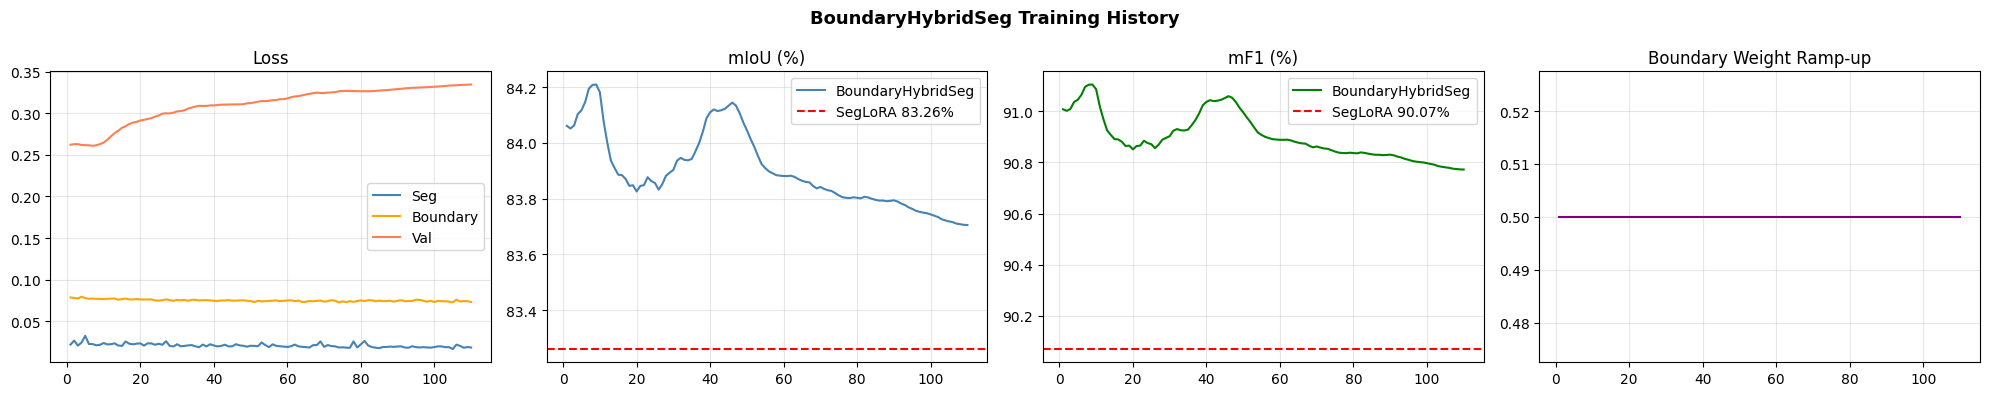

Saved : /content/drive/MyDrive/Colab Notebooks/checkpoints_journal7/BoundaryHybridSeg_v2/training_curves_boundaryhybridseg.png
Epochs plotted : 110 | Best val mIoU : 84.21% | Best val mF1  : 91.10%


In [ ]:
# ─── Cell 9 : Training Curves ───────────────────────────────────────────────────
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
        print('✅ Drive mounted')
    else:
        print('ℹ️  Drive already mounted')
except Exception:
    pass

def plot_training_curves(cfg=CFG):
    ckpt_path = Path(cfg['ckpt_dir']) / 'latest.pth'
    if not ckpt_path.exists():
        print(f'❌ File not found: {ckpt_path}')
        print('   Make sure Google Drive is mounted and Cell 2 has been run.')
        return
    state  = torch.load(ckpt_path, map_location='cpu')
    if 'history' not in state:
        print('❌ No training history found in checkpoint.'); return
    h      = state['history']
    epochs = range(1, len(h['mIoU']) + 1)
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    fig.suptitle('BoundaryHybridSeg Training History', fontsize=13, fontweight='bold')
    axes[0].plot(epochs, h['seg_loss'], label='Seg',      color='steelblue')
    axes[0].plot(epochs, h['bnd_loss'], label='Boundary', color='orange')
    axes[0].plot(epochs, h['val_loss'], label='Val',      color='coral')
    axes[0].set_title('Loss'); axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].plot(epochs, [v*100 for v in h['mIoU']], color='steelblue', label='BoundaryHybridSeg')
    axes[1].axhline(83.26, color='red', ls='--', lw=1.5, label='SegLoRA 83.26%')
    axes[1].set_title('mIoU (%)'); axes[1].legend(); axes[1].grid(alpha=0.3)
    axes[2].plot(epochs, [v*100 for v in h['mF1']], color='green', label='BoundaryHybridSeg')
    axes[2].axhline(90.07, color='red', ls='--', lw=1.5, label='SegLoRA 90.07%')
    axes[2].set_title('mF1 (%)'); axes[2].legend(); axes[2].grid(alpha=0.3)
    axes[3].plot(epochs, h['bnd_weight'], color='purple')
    axes[3].set_title('Boundary Weight Ramp-up'); axes[3].grid(alpha=0.3)
    plt.tight_layout()
    out = Path(cfg['ckpt_dir']) / 'training_curves_boundaryhybridseg.png'
    plt.savefig(str(out), dpi=150, bbox_inches='tight'); plt.show()
    print(f'Saved : {out}')
    print(f'Epochs plotted : {len(h["mIoU"])} | '
          f'Best val mIoU : {max(h["mIoU"])*100:.2f}% | '
          f'Best val mF1  : {max(h["mF1"])*100:.2f}%')


plot_training_curves(CFG)

Building loaders ...
  [train] 515 images | /content/drive/MyDrive/Colab Notebooks/tomato_project/laboro_prepared/train/images
  [val] 128 images | /content/drive/MyDrive/Colab Notebooks/tomato_project/laboro_prepared/val/images
  [test] 161 images | /content/drive/MyDrive/Colab Notebooks/tomato_project/laboro_prepared/test/images
  ✅ train=515 val=128 test=161


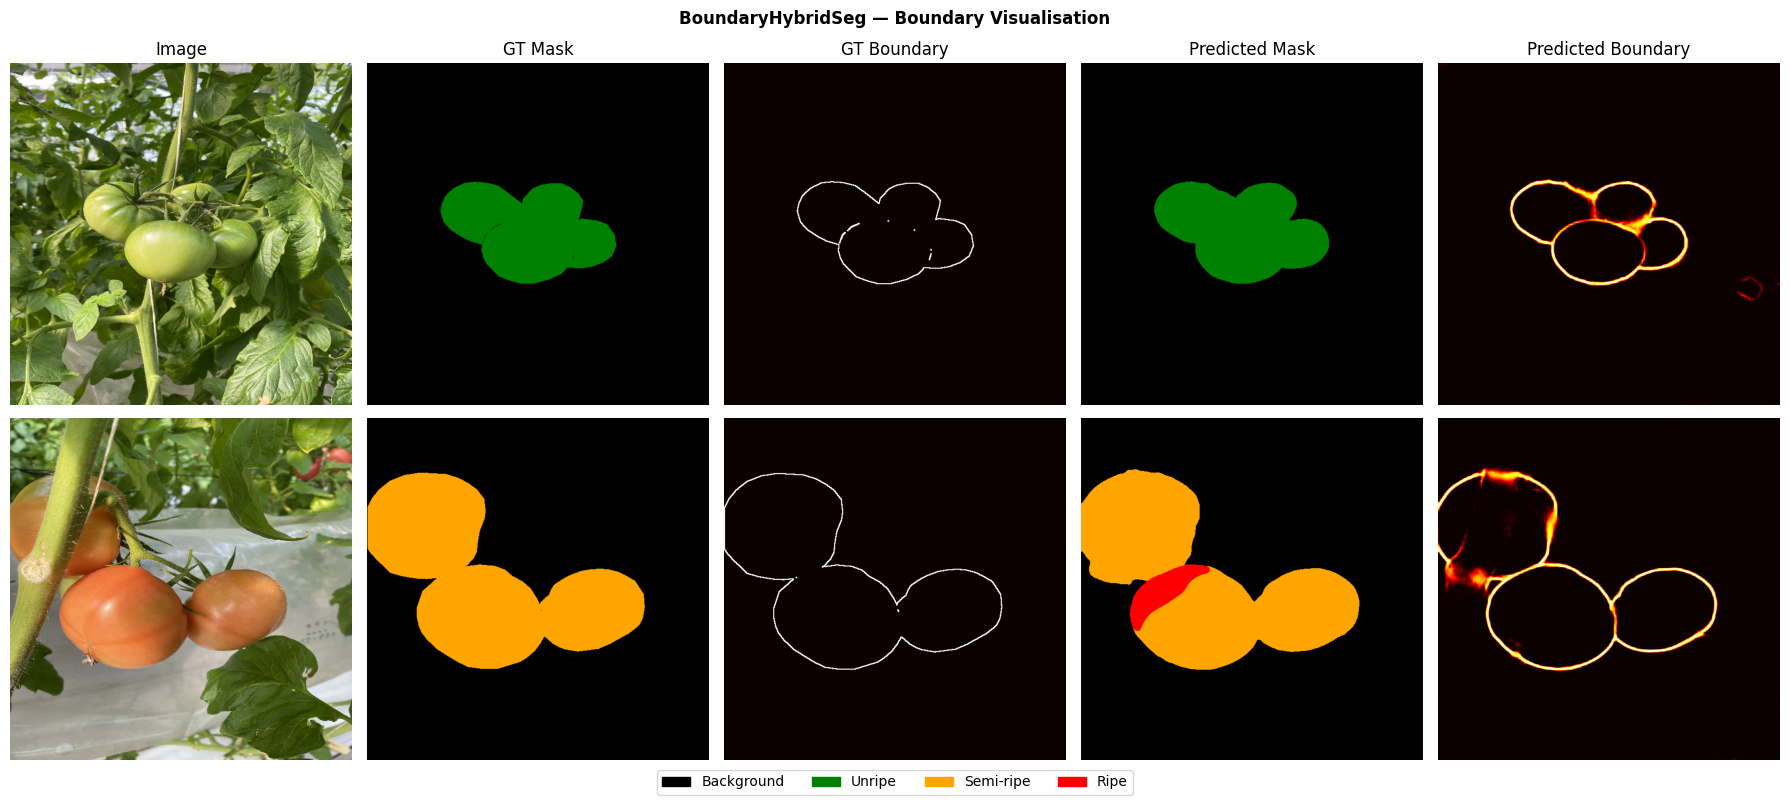

Saved : /content/drive/MyDrive/Colab Notebooks/checkpoints_journal7/BoundaryHybridSeg_v2/boundary_visualization.png


In [ ]:
# ─── Cell 10 : Boundary Map Visualisation ────────────────────────────────────────
@torch.no_grad()
def visualize_boundary(cfg=CFG, ckpt='best_miou', n=4):
    model = BoundaryHybridSeg(num_classes=cfg['num_classes'], pretrained=False).to(DEVICE)
    state = torch.load(Path(cfg['ckpt_dir']) / f'{ckpt}.pth', map_location=DEVICE)
    model.load_state_dict(state['model']); model.train()
    _, _, test_loader = build_loaders(cfg)
    imgs_b, masks_b = next(iter(test_loader))
    imgs_b = imgs_b.to(DEVICE)
    with autocast(enabled=cfg['use_amp']):
        seg_logits, bnd_logits = model(imgs_b)
    preds    = seg_logits.argmax(1).cpu().numpy()
    bnd_pred = torch.sigmoid(bnd_logits).squeeze(1).cpu().numpy()
    gt_bnd   = generate_boundary_gt(masks_b, dilation=3).squeeze(1).numpy()
    masks    = masks_b.numpy()
    mean = np.array(IMAGENET_MEAN); std = np.array(IMAGENET_STD)
    n    = min(n, len(imgs_b))
    fig, axes = plt.subplots(n, 5, figsize=(18, n * 4))
    fig.suptitle('BoundaryHybridSeg — Boundary Visualisation', fontweight='bold')
    cols  = ['Image', 'GT Mask', 'GT Boundary', 'Predicted Mask', 'Predicted Boundary']
    cmaps = [None, None, 'hot', None, 'hot']
    def mask_rgb(m):
        rgb = np.zeros((*m.shape, 3), dtype=np.uint8)
        for c, col in enumerate(CLASS_COLORS): rgb[m == c] = col
        return rgb
    for i in range(n):
        img  = (imgs_b[i].cpu().permute(1, 2, 0).numpy() * std + mean).clip(0, 1)
        data = [img, mask_rgb(masks[i]), gt_bnd[i], mask_rgb(preds[i]), bnd_pred[i]]
        for j, (d, title, cmap) in enumerate(zip(data, cols, cmaps)):
            axes[i, j].imshow(d, cmap=cmap)
            axes[i, j].set_title(title if i == 0 else '')
            axes[i, j].axis('off')
    patches = [mpatches.Patch(color=[c/255 for c in col], label=nm)
               for nm, col in zip(CLASS_NAMES, CLASS_COLORS)]
    fig.legend(handles=patches, loc='lower center', ncol=4, fontsize=10, bbox_to_anchor=(0.5, -0.01))
    plt.tight_layout()
    out = Path(cfg['ckpt_dir']) / 'boundary_visualization.png'
    plt.savefig(str(out), dpi=150, bbox_inches='tight'); plt.show()
    print(f'Saved : {out}')


visualize_boundary(CFG)

In [ ]:
# ─── Cell 11 : ONNX Export ───────────────────────────────────────────────────────
# Boundary branch excluded at inference (eval mode returns seg only)
# ONNX path : {CFG['ckpt_dir']}/BoundaryHybridSeg_{export_size}.onnx
# Uses latest.pth (epoch 300) — best test set performance

import re

def _remap_old_segformer_keys(sd):
    # Old HF SegformerModel (pre attention-refactor) -> current module names.
    # Only the encoder submodule was restructured by transformers; decoder/head
    # keys pass through unchanged since those are this notebook's own modules.
    remapped = {}
    for k, v in sd.items():
        nk = k
        nk = re.sub(r'^encoder\.encoder\.patch_embeddings\.(\d+)\.', r'encoder.stages.\1.patch_embeddings.', nk)
        nk = re.sub(r'^encoder\.encoder\.block\.(\d+)\.(\d+)\.',     r'encoder.stages.\1.blocks.\2.',        nk)
        nk = re.sub(r'^encoder\.encoder\.layer_norm\.(\d+)\.',       r'encoder.stages.\1.layer_norm.',       nk)
        nk = nk.replace('.layer_norm_1.', '.layernorm_before.')
        nk = nk.replace('.layer_norm_2.', '.layernorm_after.')
        nk = nk.replace('.attention.self.query.', '.attention.q_proj.')
        nk = nk.replace('.attention.self.key.',   '.attention.k_proj.')
        nk = nk.replace('.attention.self.value.', '.attention.v_proj.')
        nk = nk.replace('.attention.self.sr.',         '.attention.sequence_reduction.sequence_reduction.')
        nk = nk.replace('.attention.self.layer_norm.', '.attention.sequence_reduction.layer_norm.')
        nk = nk.replace('.attention.output.dense.', '.attention.o_proj.')
        nk = nk.replace('.mlp.dense1.', '.mlp.fc1.')
        nk = nk.replace('.mlp.dense2.', '.mlp.fc2.')
        remapped[nk] = v
    return remapped


def export_onnx(cfg=CFG, ckpt='latest', export_size=512, opset=17, dynamic_batch=True):
    # dynamic_batch=False + opset=13 is the Hailo-friendly export: a fixed batch
    # axis and decomposed LayerNorm ops (pre opset-17) parse more reliably on the
    # Hailo DFC than a dynamic batch dim or the native LayerNormalization op.
    ckpt_path = Path(cfg['ckpt_dir']) / f'{ckpt}.pth'
    suffix    = '' if (opset == 17 and dynamic_batch) else f'_op{opset}' + ('' if dynamic_batch else '_static')
    out_path  = Path(cfg['ckpt_dir']) / f'BoundaryHybridSeg_{export_size}{suffix}.onnx'
    if not ckpt_path.exists():
        print(f'❌ Checkpoint not found: {ckpt_path}'); return
    model = BoundaryHybridSeg(num_classes=cfg['num_classes'], pretrained=False,
                              encoder=cfg['encoder']).cpu().float()
    state = torch.load(ckpt_path, map_location='cpu')
    sd = state['model']
    try:
        model.load_state_dict(sd)
    except RuntimeError:
        print('⚠️  state_dict key mismatch (transformers version drift since training) — remapping...')
        sd = _remap_old_segformer_keys(sd)
        missing, unexpected = model.load_state_dict(sd, strict=False)
        if missing or unexpected:
            print(f'   Still missing   : {missing}')
            print(f'   Still unexpected: {unexpected}')
            raise RuntimeError('Remap incomplete -- see keys above; consider pinning an older transformers version instead')
        print('   ✅ Remap successful, all keys matched')
    model.eval()
    dummy = torch.randn(1, 3, export_size, export_size, dtype=torch.float32)
    with torch.no_grad(): out = model(dummy)
    print(f'Forward check : {tuple(dummy.shape)} → {tuple(out.shape)}')
    dyn_axes = {'image': {0: 'batch'}, 'logits': {0: 'batch'}} if dynamic_batch else None
    torch.onnx.export(
        model, dummy, str(out_path),
        input_names=['image'], output_names=['logits'],
        dynamic_axes=dyn_axes,
        opset_version=opset, do_constant_folding=True, verbose=False)
    import onnx
    actual_opset = onnx.load(str(out_path)).opset_import[0].version
    size_mb = out_path.stat().st_size / 1e6
    print(f'✅ Exported  : {out_path}')
    print(f'   Checkpoint: {ckpt}.pth  (epoch {state["epoch"]})')
    print(f'   Size      : {size_mb:.1f} MB')
    print(f'   Opset     : {actual_opset}  (actual from file)')
    print(f'   Input     : [1, 3, {export_size}, {export_size}]  float32')
    print(f'   Output    : [1, 4, {export_size}, {export_size}]  float32')
    print(f'   Note      : Boundary branch excluded from ONNX')
    import time
    reps = 5; t0 = time.time()
    with torch.no_grad():
        for _ in range(reps): _ = model(dummy)
    cpu_ms = (time.time() - t0) / reps * 1000
    print(f'\n  CPU latency : {cpu_ms:.0f} ms/frame @ {export_size}px')
    print(f'  RPi5 est.   : ~{cpu_ms*8:.0f}–{cpu_ms*15:.0f} ms/frame')
    return str(out_path)


export_onnx(cfg=CFG, ckpt='latest', export_size=512)
# export_onnx(cfg=CFG, ckpt='latest', export_size=256)  # uncomment for RPi5
# export_onnx(cfg=CFG, ckpt='latest', export_size=512, opset=18, dynamic_batch=False)  # Hailo-friendly static export (opset 13 unreachable: this PyTorch's exporter can't downgrade below 18 for this model's Resize nodes)

Forward check : (1, 3, 512, 512) → (1, 4, 512, 512)


W0823 19:58:24.957000 3088 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", lin

✅ Exported  : /content/drive/MyDrive/Colab Notebooks/checkpoints_journal7/BoundaryHybridSeg_v2/BoundaryHybridSeg_512.onnx
   Checkpoint: latest.pth  (epoch 300)
   Size      : 6.8 MB
   Opset     : 18  (actual from file)
   Input     : [1, 3, 512, 512]  float32
   Output    : [1, 4, 512, 512]  float32
   Note      : Boundary branch excluded from ONNX

  CPU latency : 3274 ms/frame @ 512px
  RPi5 est.   : ~26192–49111 ms/frame


'/content/drive/MyDrive/Colab Notebooks/checkpoints_journal7/BoundaryHybridSeg_v2/BoundaryHybridSeg_512.onnx'

In [ ]:
export_onnx(cfg=CFG, ckpt='latest', export_size=512, opset=18, dynamic_batch=False)

In [ ]:
# ─── Cell 12 : Results Table ────────────────────────────────────────────────────
def print_results_table(test_results=None):
    SEP = '─' * 82
    print(SEP)
    print(f'{"Method":<38} {"mIoU":>8} {"mF1":>8} {"PixAcc":>8} {"BalAcc":>8}')
    print(SEP)
    baselines = [
        ('SegLoRA    (MiT-B4+LoRA)',           83.26, 90.07, '—',     '93.88'),
    ]
    for r in baselines:
        print(f'{r[0]:<38} {str(r[1]):>8} {str(r[2]):>8} {str(r[3]):>8} {str(r[4]):>8}')
    if test_results:
        r = test_results
        print(f'{"BoundaryHybridSeg":<38} '
              f'{r["mIoU"]*100:>8.2f} '
              f'{r["mF1"]*100:>8.2f} '
              f'{r["Accuracy"]*100:>8.2f} '
              f'{r["BalAcc"]*100:>8.2f}')
    print(SEP)
    print('NOTE: All results from test set (Laboro Tomato). Epoch 300 checkpoint.')
    if test_results:
        print(f'\n  Gap vs SegLoRA : mIoU {test_results["mIoU"]*100-83.26:+.2f}%  '
              f'mF1 {test_results["mF1"]*100-90.07:+.2f}%')
    print(SEP)


print_results_table(test_results=results)

──────────────────────────────────────────────────────────────────────────────────
Method                                     mIoU      mF1   PixAcc   BalAcc
──────────────────────────────────────────────────────────────────────────────────
SegLoRA    (MiT-B4+LoRA)                  83.26    90.07        —    93.88
BoundaryHybridSeg                         84.28    91.10    98.33    91.73
──────────────────────────────────────────────────────────────────────────────────
NOTE: All results from test set (Laboro Tomato). Epoch 300 checkpoint.

  Gap vs SegLoRA : mIoU +1.02%  mF1 +1.03%
──────────────────────────────────────────────────────────────────────────────────


---
## Cell 13 — Ablation Study *(Optional)*

Run **only if needed** (journal requirement or BoundaryHybridSeg doesn't beat SegLoRA).

| Variant | BoundaryLoss | BoundaryGuidedAttn | Purpose |
|---|---|---|---|
| A | ❌ | ❌ | HybridSeg baseline |
| B | ✅ | ❌ | Loss contribution only |
| C | ❌ | ✅ | Attention contribution only |
| D (Full) | ✅ | ✅ | Complete BoundaryHybridSeg |

> Set `ablation_epochs=150` for speed or `ablation_epochs=300` for publication quality.

In [ ]:
# ─── Cell 13 : Ablation Study (OPTIONAL) ──────────────────────────────────────
ABLATION_VARIANTS = [
    {'name': 'A — Baseline (No Boundary)', 'use_boundary_loss': False, 'use_boundary_attn': False, 'ckpt_tag': 'ablation_A_baseline'},
    {'name': 'B — BoundaryLoss only',      'use_boundary_loss': True,  'use_boundary_attn': False, 'ckpt_tag': 'ablation_B_bndloss'},
    {'name': 'C — BoundaryGuidedAttn only','use_boundary_loss': False, 'use_boundary_attn': True,  'ckpt_tag': 'ablation_C_bndattn'},
    {'name': 'D — Full BoundaryHybridSeg', 'use_boundary_loss': True,  'use_boundary_attn': True,  'ckpt_tag': 'ablation_D_full'},
]


def run_ablation(cfg=CFG, ablation_epochs=150):
    ablation_results = []
    for variant in ABLATION_VARIANTS:
        print(f'\n{"="*65}')
        print(f'  Variant : {variant["name"]}  |  Epochs : {ablation_epochs}')
        print(f'  BndLoss : {variant["use_boundary_loss"]}  |  BndAttn : {variant["use_boundary_attn"]}')
        print(f'{"="*65}')
        abl_cfg = dict(cfg)
        abl_cfg['epochs']          = ablation_epochs
        abl_cfg['resume_from']     = None
        if not variant['use_boundary_loss']:
            abl_cfg['boundary_weight'] = 0.0
        model = BoundaryHybridSeg(
            num_classes=abl_cfg['num_classes'], pretrained=abl_cfg['pretrained'],
            encoder=abl_cfg['encoder'], use_boundary_attn=variant['use_boundary_attn']).to(DEVICE)
        criterion  = CombinedLoss(abl_cfg)
        metrics    = SegMetrics(abl_cfg['num_classes'])
        optimizer  = torch.optim.AdamW(model.get_param_groups(abl_cfg['encoder_lr'], abl_cfg['decoder_lr'], abl_cfg['weight_decay']))
        train_loader, val_loader, test_loader = build_loaders(abl_cfg)
        steps_per_epoch = math.ceil(len(train_loader) / abl_cfg['accum_steps'])
        scheduler = torch.optim.lr_scheduler.OneCycleLR(
            optimizer, max_lr=[abl_cfg['encoder_lr'], abl_cfg['decoder_lr']],
            epochs=ablation_epochs, steps_per_epoch=steps_per_epoch,
            pct_start=0.10, anneal_strategy='cos', div_factor=10, final_div_factor=100)
        scaler = GradScaler(enabled=abl_cfg['use_amp'])
        best_miou = 0.0; best_state = None

        for epoch in range(1, ablation_epochs + 1):
            model.train()
            bnd_weight = get_boundary_weight(epoch, abl_cfg)
            optimizer.zero_grad()
            for step, (imgs, masks) in enumerate(train_loader):
                imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
                with autocast(enabled=abl_cfg['use_amp']):
                    seg_logits, bnd_logits = model(imgs)
                    loss, _, _ = criterion(seg_logits, bnd_logits, masks, bnd_weight)
                    loss = loss / abl_cfg['accum_steps']
                scaler.scale(loss).backward()
                if (step + 1) % abl_cfg['accum_steps'] == 0 or (step + 1) == len(train_loader):
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(optimizer); scaler.update()
                    optimizer.zero_grad(); scheduler.step()
            _, res = evaluate(model, val_loader, criterion, metrics, abl_cfg)
            if res['mIoU'] > best_miou:
                best_miou = res['mIoU']
                best_state = {'model': model.state_dict(), 'epoch': epoch}
            if epoch % 30 == 0:
                print(f'  [{epoch:03d}] mIoU={res["mIoU"]*100:.2f}%  Semi-ripe={res["IoU"][2]*100:.2f}%')

        torch.save(best_state, Path(abl_cfg['ckpt_dir']) / f'{variant["ckpt_tag"]}.pth')
        model.load_state_dict(best_state['model']); model.eval(); metrics.reset()
        with torch.no_grad():
            for imgs, masks in test_loader:
                imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
                with autocast(enabled=abl_cfg['use_amp']):
                    seg_logits = model(imgs)
                metrics.update(seg_logits.argmax(1), masks)
        test_res = metrics.compute()
        ablation_results.append({'name': variant['name'], 'mIoU': test_res['mIoU']*100,
                                  'mF1': test_res['mF1']*100, 'semi_iou': test_res['IoU'][2]*100,
                                  'pixel_acc': test_res['Accuracy']*100})
        print(f'  ✅ {variant["name"]} | mIoU={test_res["mIoU"]*100:.2f}%  Semi-ripe={test_res["IoU"][2]*100:.2f}%')
        torch.cuda.empty_cache()

    SEP = '─' * 80
    print(f'\n{SEP}')
    print(f'  Ablation Study Results — BoundaryHybridSeg')
    print(SEP)
    print(f'  {"Variant":<35} {"mIoU":>8} {"mF1":>8} {"Semi-ripe":>10} {"PixAcc":>8}')
    print(SEP)
    print(f'  {"[Ref] SegLoRA":<35} {"83.26":>8} {"90.07":>8} {"  —":>10} {"  —":>8}')
    print(SEP)
    for r in ablation_results:
        print(f'  {r["name"]:<35} {r["mIoU"]:>8.2f} {r["mF1"]:>8.2f} {r["semi_iou"]:>9.2f}% {r["pixel_acc"]:>8.2f}')
    if len(ablation_results) == 4:
        base = ablation_results[0]
        print(SEP)
        print('  Delta vs Variant A (baseline):')
        for r in ablation_results[1:]:
            print(f'  {r["name"]:<35} mIoU {r["mIoU"]-base["mIoU"]:>+6.2f}%  Semi-ripe {r["semi_iou"]-base["semi_iou"]:>+6.2f}%')
    print(SEP)
    out = Path(cfg['ckpt_dir']) / 'ablation_results.txt'
    with open(str(out), 'w') as f:
        for r in ablation_results:
            f.write(f'{r["name"]:<35} mIoU={r["mIoU"]:.2f} mF1={r["mF1"]:.2f} Semi={r["semi_iou"]:.2f}\n')
    print(f'  Saved : {out}')
    return ablation_results


# ablation_epochs=150  → faster (~half time per variant)
# ablation_epochs=300  → full training, publication quality
ablation_results = run_ablation(cfg=CFG, ablation_epochs=150)